# Dibuja y aprende — Paso 2: modelos

Se comparan, de lo más simple a lo más complejo, los modelos vistos en el curso:

| # | Modelo | Qué ve |
|---|---|---|
| 0 | Línea base (azar) | nada |
| 1 | SVM (kernels lineal, RBF, polinomial) y Random Forest | los 784 píxeles como columnas sueltas |
| 2 | ANN (red densa) | los 784 píxeles, sin saber cuáles son vecinos |
| 3 | CNN propia | la imagen, con filtros que detectan bordes y formas |
| 4 | Transfer learning (MobileNetV2) | la imagen, con lo que aprendió de fotos (ImageNet) |

**Tipo de problema:** clasificación multiclase (la salida es una palabra entre 40, no un número continuo). Las clases están **balanceadas** por diseño (mismo número de dibujos por palabra), así que el accuracy es comparable entre palabras; igual se reporta F1 por palabra.

> Activar GPU: Entorno de ejecución → Cambiar tipo → T4 GPU.

## 1. Carga de datos

In [1]:
import os, json, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

BASE = Path("/content")
DRIVE = Path("/content/drive/MyDrive/proyecto_dibujos")
USAR_DRIVE = True
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    for archivo in ["dibujos_datos.npz", "palabras.json", "temas.json", "dibujos.py"]:
        if not (BASE / archivo).exists():
            shutil.copy(DRIVE / archivo, BASE / archivo)

datos = np.load(BASE / "dibujos_datos.npz")
PALABRAS = json.load(open(BASE / "palabras.json", encoding="utf-8"))
CLASES = list(PALABRAS)
N = len(CLASES)

X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]
X_noreco, y_noreco = datos["X_no_reconocidos"], datos["y_no_reconocidos"]
X_col, y_col = datos["X_colombia"], datos["y_colombia"]
col_reco = datos["colombia_reconocido"]

print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)
print("no reconocidos", X_noreco.shape, "| Colombia", X_col.shape)
print("GPU:", tf.config.list_physical_devices("GPU"))

EPOCAS = 30

Mounted at /content/drive
train (224000, 28, 28) | val (48000, 28, 28) | test (48000, 28, 28)
no reconocidos (40000, 28, 28) | Colombia (7732, 28, 28)
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
resultados = []

def registrar(nombre, y_pred, params=None, seg_entreno=None, seg_por_dibujo=None, mb=None, y_pred_val=None):
    fila = {
        "modelo": nombre,
        "F1 macro val": None if y_pred_val is None else f1_score(y_val, y_pred_val, average="macro"),
        "accuracy": accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "parámetros": params,
        "entrenamiento (s)": None if seg_entreno is None else round(seg_entreno, 1),
        "ms por dibujo": None if seg_por_dibujo is None else round(1000 * seg_por_dibujo, 3),
        "tamaño (MB)": mb,
    }
    resultados.append(fila)
    print(f"{nombre}: F1 val {fila['F1 macro val'] or 0:.4f} | accuracy prueba {fila['accuracy']:.4f} | F1 prueba {fila['F1 macro']:.4f}")

# Línea base: adivinar al azar acierta 1 de cada N palabras
registrar("0. Azar", np.random.default_rng(SEED).integers(0, N, len(y_test)),
          y_pred_val=np.random.default_rng(SEED + 1).integers(0, N, len(y_val)))

0. Azar: F1 val 0.0260 | accuracy prueba 0.0252 | F1 prueba 0.0252


## 2. Modelos clásicos: SVM y Random Forest

Igual que en el primer corte. Para que el SVM entrene en un tiempo razonable:
- se usa una submuestra de 500 dibujos por palabra (10.000 en total);
- se reducen los 784 píxeles a 60 componentes con **PCA**, que conserva la mayor parte de la información.

In [3]:
POR_CLASE = 500
rng = np.random.default_rng(SEED)
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], min(POR_CLASE, (y_train == c).sum()), replace=False) for c in range(N)])

plano = lambda X: X.reshape(len(X), -1).astype(np.float32) / 255.0
pca = PCA(n_components=60, random_state=SEED).fit(plano(X_train[sub]))
print(f"Varianza conservada con 60 componentes: {pca.explained_variance_ratio_.sum():.1%}")
Z_sub, Z_val, Z_test = pca.transform(plano(X_train[sub])), pca.transform(plano(X_val)), pca.transform(plano(X_test))

Varianza conservada con 60 componentes: 65.2%


In [4]:
for kernel in ["linear", "rbf", "poly"]:
    t0 = time.time()
    svm = SVC(kernel=kernel, C=5 if kernel != "linear" else 1, random_state=SEED).fit(Z_sub, y_train[sub])
    t1 = time.time()
    pred = svm.predict(Z_test)
    registrar(f"1. SVM {kernel}", pred, seg_entreno=t1 - t0, seg_por_dibujo=(time.time() - t1) / len(Z_test),
              y_pred_val=svm.predict(Z_val))

1. SVM linear: F1 val 0.5898 | accuracy prueba 0.5961 | F1 prueba 0.5961
1. SVM rbf: F1 val 0.7339 | accuracy prueba 0.7362 | F1 prueba 0.7356
1. SVM poly: F1 val 0.7270 | accuracy prueba 0.7256 | F1 prueba 0.7253


In [5]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(plano(X_train[sub]), y_train[sub])
t1 = time.time()
registrar("1. Random Forest", rf.predict(plano(X_test)), seg_entreno=t1 - t0, seg_por_dibujo=(time.time() - t1) / len(X_test),
          y_pred_val=rf.predict(plano(X_val)))

1. Random Forest: F1 val 0.6150 | accuracy prueba 0.6329 | F1 prueba 0.6170


## 3. Redes en Keras

Detalles comunes:
- La **normalización** (dividir por 255) va **dentro del modelo** (`Rescaling`), como dice la guía de despliegue: la app solo le pasa la imagen de 0 a 255.
- Pérdida `sparse_categorical_crossentropy` (las etiquetas son números enteros), salida `softmax` con una neurona por palabra, optimizador Adam.
- `EarlyStopping` (para cuando la validación deja de mejorar y recupera los mejores pesos) y `ReduceLROnPlateau`.

In [6]:
def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

def entrenar(modelo, nombre, X_tr=X_train, y_tr=y_train, lr=1e-3, epocas=EPOCAS, batch=128):
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = modelo.fit(X_tr[..., None], y_tr, validation_data=(X_val[..., None], y_val),
                      epochs=epocas, batch_size=batch, callbacks=callbacks(), verbose=2)
    return hist, time.time() - t0

def evaluar_keras(modelo, nombre, hist, seg):
    t0 = time.time()
    prob = modelo.predict(X_test[..., None], batch_size=512, verbose=0)
    seg_pred = (time.time() - t0) / len(X_test)
    ruta = BASE / f"{nombre.split('.')[0].strip()}_tmp.keras"
    modelo.save(ruta)
    prob_v = modelo.predict(X_val[..., None], batch_size=512, verbose=0)
    registrar(nombre, prob.argmax(1), params=modelo.count_params(), seg_entreno=seg,
              seg_por_dibujo=seg_pred, mb=round(os.path.getsize(ruta) / 1e6, 2), y_pred_val=prob_v.argmax(1))
    return prob

def curvas(hist, titulo):
    h = pd.DataFrame(hist.history)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    h[["loss", "val_loss"]].plot(ax=ax[0], title=f"{titulo} — pérdida")
    h[["accuracy", "val_accuracy"]].plot(ax=ax[1], title=f"{titulo} — accuracy")
    for a in ax: a.set_xlabel("época"); a.grid(True)
    plt.tight_layout(); plt.show()

### 3.1 ANN (red densa)

Aplana la imagen en 784 números. No sabe qué píxeles son vecinos: un trazo movido un poco a la derecha es, para ella, una entrada totalmente distinta.

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 40)             │         5,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 239,016 (933.66 KB)

 Trainable params: 239,016 (933.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1750/1750 - 9s - 5ms/step - accuracy: 0.5302 - loss: 1.7090 - val_accuracy: 0.6758 - val_loss: 1.1502 - learning_rate: 0.0010
Epoch 2/30
1750/1750 - 6s - 3ms/step - accuracy: 0.6367 - loss: 1.2966 - val_accuracy: 0.7089 - val_loss: 1.0247 - learning_rate: 0.0010
Epoch 3/30
1750/1750 - 5s - 3ms/step - accuracy: 0.6646 - loss: 1.1909 - val_accuracy: 0.7253 - val_loss: 0.9580 - learning_rate: 0.0010
Epoch 4/30
1750/1750 - 6s - 3ms/step - accuracy: 0.6793 - loss: 1.1323 - val_accuracy: 0.7365 - val_loss: 0.9218 - learning_rate: 0.0010
Epoch 5/30
1750/1750 - 5s - 3ms/step - accuracy: 0.6890 - loss: 1.0902 - val_accuracy: 0.7441 - val_loss: 0.8891 - learning_rate: 0.0010
Epoch 6/30
1750/1750 - 5s - 3ms/step - accuracy: 0.6979 - loss: 1.0565 - val_accuracy: 0.7499 - val_loss: 0.8677 - learning_rate: 0.0010
Epoch 7/30
1750/1750 - 6s - 4ms/step - accuracy: 0.7025 - loss: 1.0399 - val_accuracy: 0.7533 - val_loss: 0.8559 - learning_rate: 0.0010
Epoch 8/30
1750/1750 - 5s - 3ms/step - ac

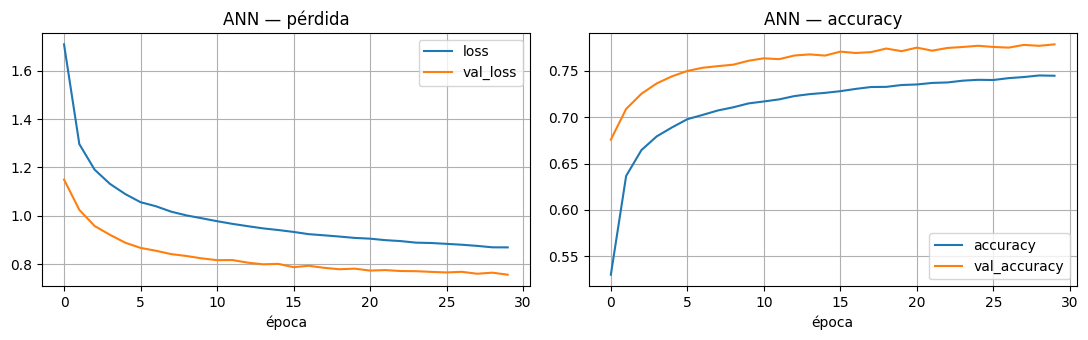

2. ANN: F1 val 0.7762 | accuracy prueba 0.7790 | F1 prueba 0.7767


In [7]:
ann = keras.Sequential([
    keras.Input((28, 28, 1)),
    layers.Rescaling(1 / 255.0),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(N, activation="softmax"),
], name="ANN")
ann.summary()
hist_ann, seg = entrenar(ann, "ANN")
curvas(hist_ann, "ANN")
prob_ann = evaluar_keras(ann, "2. ANN", hist_ann, seg)

### 3.2 CNN propia

Los filtros convolucionales recorren la imagen y detectan bordes, curvas y luego formas (orejas, ruedas, pétalos), sin importar dónde estén.

**Data augmentation** (solo se activa al entrenar): pequeños giros, zoom, desplazamientos y espejo horizontal. Así el modelo aguanta que la gente dibuje un poco torcido o descentrado.

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 309,448 (1.18 MB)

 Trainable params: 308,552 (1.18 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/30
1750/1750 - 50s - 29ms/step - accuracy: 0.5769 - loss: 1.4712 - val_accuracy: 0.7499 - val_loss: 0.8529 - learning_rate: 0.0010
Epoch 2/30
1750/1750 - 40s - 23ms/step - accuracy: 0.7604 - loss: 0.8096 - val_accuracy: 0.8131 - val_loss: 0.6082 - learning_rate: 0.0010
Epoch 3/30
1750/1750 - 39s - 22ms/step - accuracy: 0.7986 - loss: 0.6781 - val_accuracy: 0.8338 - val_loss: 0.5454 - learning_rate: 0.0010
Epoch 4/30
1750/1750 - 40s - 23ms/step - accuracy: 0.8187 - loss: 0.6096 - val_accuracy: 0.8558 - val_loss: 0.4693 - learning_rate: 0.0010
Epoch 5/30
1750/1750 - 40s - 23ms/step - accuracy: 0.8316 - loss: 0.5656 - val_accuracy: 0.8500 - val_loss: 0.4851 - learning_rate: 0.0010
Epoch 6/30
1750/1750 - 40s - 23ms/step - accuracy: 0.8410 - loss: 0.5347 - val_accuracy: 0.8810 - val_loss: 0.3853 - learning_rate: 0.0010
Epoch 7/30
1750/1750 - 40s - 23ms/step - accuracy: 0.8478 - loss: 0.5115 - val_accuracy: 0.8716 - val_loss: 0.4206 - learning_rate: 0.0010
Epoch 8/30
1750/1750 - 40s 

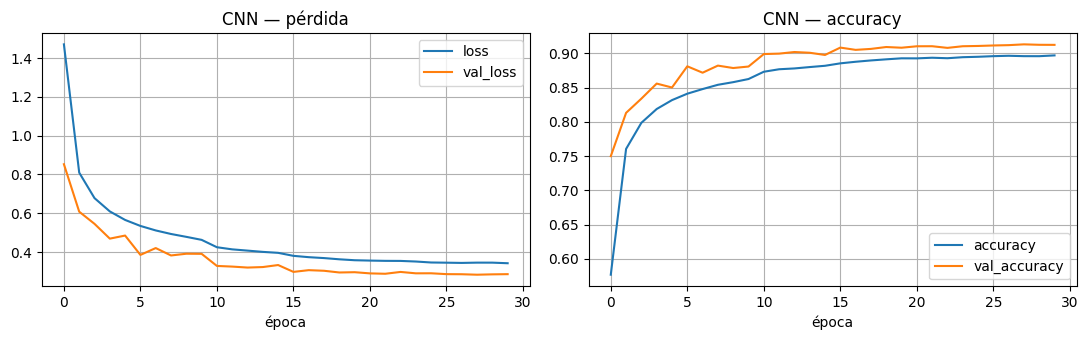

3. CNN: F1 val 0.9124 | accuracy prueba 0.9143 | F1 prueba 0.9137


In [8]:
def crear_aumento():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.08, 0.08),
    ], name="aumento")

def bloque(x, filtros):
    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)

entrada = keras.Input((28, 28, 1))
x = layers.Rescaling(1 / 255.0)(entrada)
x = crear_aumento()(x)
x = bloque(x, 32)          # 28 -> 14
x = bloque(x, 64)          # 14 -> 7
x = bloque(x, 128)         # 7 -> 3
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(N, activation="softmax")(x)
cnn = keras.Model(entrada, salida, name="CNN")
cnn.summary()

hist_cnn, seg = entrenar(cnn, "CNN")
curvas(hist_cnn, "CNN")
prob_cnn = evaluar_keras(cnn, "3. CNN", hist_cnn, seg)

### 3.3 Transfer learning (MobileNetV2)

Igual que en el Parcial 3: base preentrenada en ImageNet, primero congelada (extracción de características) y después se descongelan las últimas capas (*fine-tuning*) con la BatchNorm congelada.

Ajustes necesarios:
- MobileNetV2 espera imágenes a color de al menos 32×32 → se agranda a 96×96 y se repite el canal gris 3 veces.
- Espera píxeles en [-1, 1] → `Rescaling(1/127.5, offset=-1)` dentro del modelo.
- Por tiempo, se entrena con 2.000 dibujos por palabra.

**Pregunta que responde:** ¿sirve lo aprendido de *fotos* para reconocer *dibujos a mano*?

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
625/625 - 46s - 74ms/step - accuracy: 0.6316 - loss: 1.2926 - val_accuracy: 0.7673 - val_loss: 0.7898 - learning_rate: 0.0010
Epoch 2/10
625/625 - 39s - 62ms/step - accuracy: 0.7344 - loss: 0.8913 - val_accuracy: 0.7892 - val_loss: 0.7089 - learning_rate: 0.0010
Epoch 3/10
625/625 - 39s - 62ms/step - accuracy: 0.7535 - loss: 0.8280 - val_accuracy: 0.7976 - val_loss: 0.6810 - learning_rate: 0.0010
Epoch 4/10
625/625 - 39s - 62ms/step - accuracy: 0.7580 - loss: 0.8095 - val_accuracy: 0.8030 - val_loss: 0.6630 - learning_rate: 0.0010
Epoch 5/10
625/625 - 39s - 62ms/step - accuracy: 0.7643 - loss: 0.7879 - val_accuracy: 0.8009 - val_loss: 0.6689 - learning_rate: 0.0010
Epoch 6/10
625/625 - 39s - 62ms/step - accuracy: 0.7643 - loss: 0.7862 - val_accuracy: 0.8046 - val_loss: 0.6580 - learning_rate: 0.0010
Epoch 7/10
625/625 - 45s - 73ms/step - accuracy: 0.7658 - loss: 0.7824 - val_accuracy: 0.8073 - val_loss: 0.6507 - learning_rate:

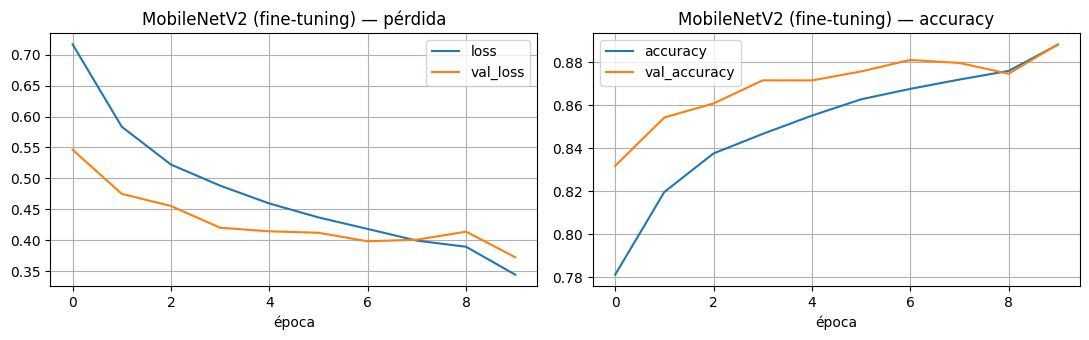

4. MobileNetV2 TL: F1 val 0.8890 | accuracy prueba 0.8905 | F1 prueba 0.8911


In [9]:
POR_CLASE_TL = 2000
sub_tl = np.concatenate([rng.choice(np.where(y_train == c)[0], min(POR_CLASE_TL, (y_train == c).sum()), replace=False) for c in range(N)])

base = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights="imagenet")
base.trainable = False

entrada = keras.Input((28, 28, 1))
x = layers.Resizing(96, 96)(entrada)
x = layers.Concatenate()([x, x, x])                 # gris -> 3 canales
x = layers.Rescaling(1 / 127.5, offset=-1)(x)       # [0,255] -> [-1,1]
x = crear_aumento()(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(N, activation="softmax")(x)
tl = keras.Model(entrada, salida, name="MobileNetV2_TL")

hist_tl1, seg1 = entrenar(tl, "TL", X_train[sub_tl], y_train[sub_tl], lr=1e-3, epocas=max(1, EPOCAS // 3))

# Fine-tuning: últimas 30 capas, BatchNorm congelada
base.trainable = True
for capa in base.layers[:-30]:
    capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False
hist_tl2, seg2 = entrenar(tl, "TL", X_train[sub_tl], y_train[sub_tl], lr=1e-4, epocas=max(1, EPOCAS // 3))
curvas(hist_tl2, "MobileNetV2 (fine-tuning)")
prob_tl = evaluar_keras(tl, "4. MobileNetV2 TL", hist_tl2, seg1 + seg2)

## 4. Comparación

,F1 macro val,accuracy,F1 macro,parámetros,entrenamiento (s),ms por dibujo,tamaño (MB)
modelo,,,,,,,
0. Azar,0.026,0.025,0.025,—,—,—,—
1. SVM linear,0.590,0.596,0.596,—,36.900000,1.399000,—
1. SVM rbf,0.734,0.736,0.736,—,22.900000,2.968000,—
1. SVM poly,0.727,0.726,0.725,—,27.400000,1.614000,—
1. Random Forest,0.615,0.633,0.617,—,77.400000,0.106000,—
2. ANN,0.776,0.779,0.777,239016.000000,171.700000,0.026000,2.900000
3. CNN,0.912,0.914,0.914,309448.000000,1206.100000,0.064000,3.840000
4. MobileNetV2 TL,0.889,0.891,0.891,2309224.000000,922.500000,0.394000,22.350000


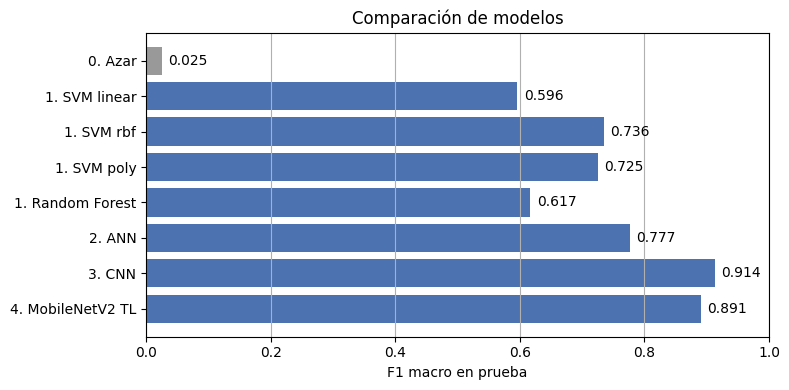

In [10]:
tabla = pd.DataFrame(resultados).set_index("modelo")
display(tabla.style.format({"F1 macro val": "{:.3f}", "accuracy": "{:.3f}", "F1 macro": "{:.3f}"}, na_rep="—"))

plt.figure(figsize=(8, 4))
plt.barh(tabla.index, tabla["F1 macro"], color=["#999"] + ["#4C72B0"] * (len(tabla) - 1))
plt.gca().invert_yaxis(); plt.xlim(0, 1); plt.xlabel("F1 macro en prueba"); plt.grid(axis="x")
for i, v in enumerate(tabla["F1 macro"]):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.title("Comparación de modelos"); plt.tight_layout(); plt.show()

## 5. Análisis del mejor modelo

El modelo se elige con **validación** (F1 macro en validación), no con prueba: la prueba solo se usa al final para confirmar. Si se eligiera mirando la prueba, ese número dejaría de ser una medida limpia. Para la app también importan el tamaño y la velocidad.

In [11]:
candidatos = {"2. ANN": (ann, prob_ann), "3. CNN": (cnn, prob_cnn), "4. MobileNetV2 TL": (tl, prob_tl)}
mejor_nombre = max(candidatos, key=lambda k: tabla.loc[k, "F1 macro val"])
mejor, prob = candidatos[mejor_nombre]
pred = prob.argmax(1)
print("Mejor modelo (por validación):", mejor_nombre)
print(classification_report(y_test, pred, target_names=CLASES, digits=3))

Mejor modelo (por validación): 3. CNN
              precision    recall  f1-score   support

       apple      0.906     0.953     0.929      1200
        pear      0.967     0.925     0.945      1200
      banana      0.870     0.890     0.880      1200
  strawberry      0.930     0.922     0.926      1200
  watermelon      0.892     0.896     0.894      1200
      grapes      0.945     0.904     0.924      1200
   ice cream      0.976     0.962     0.969      1200
       pizza      0.905     0.964     0.934      1200
         cat      0.893     0.843     0.868      1200
         dog      0.727     0.621     0.670      1200
      rabbit      0.888     0.921     0.904      1200
        bird      0.908     0.801     0.851      1200
   butterfly      0.938     0.950     0.944      1200
        fish      0.960     0.948     0.954      1200
       snake      0.904     0.943     0.923      1200
         cow      0.813     0.884     0.847      1200
        frog      0.742     0.751     0.746

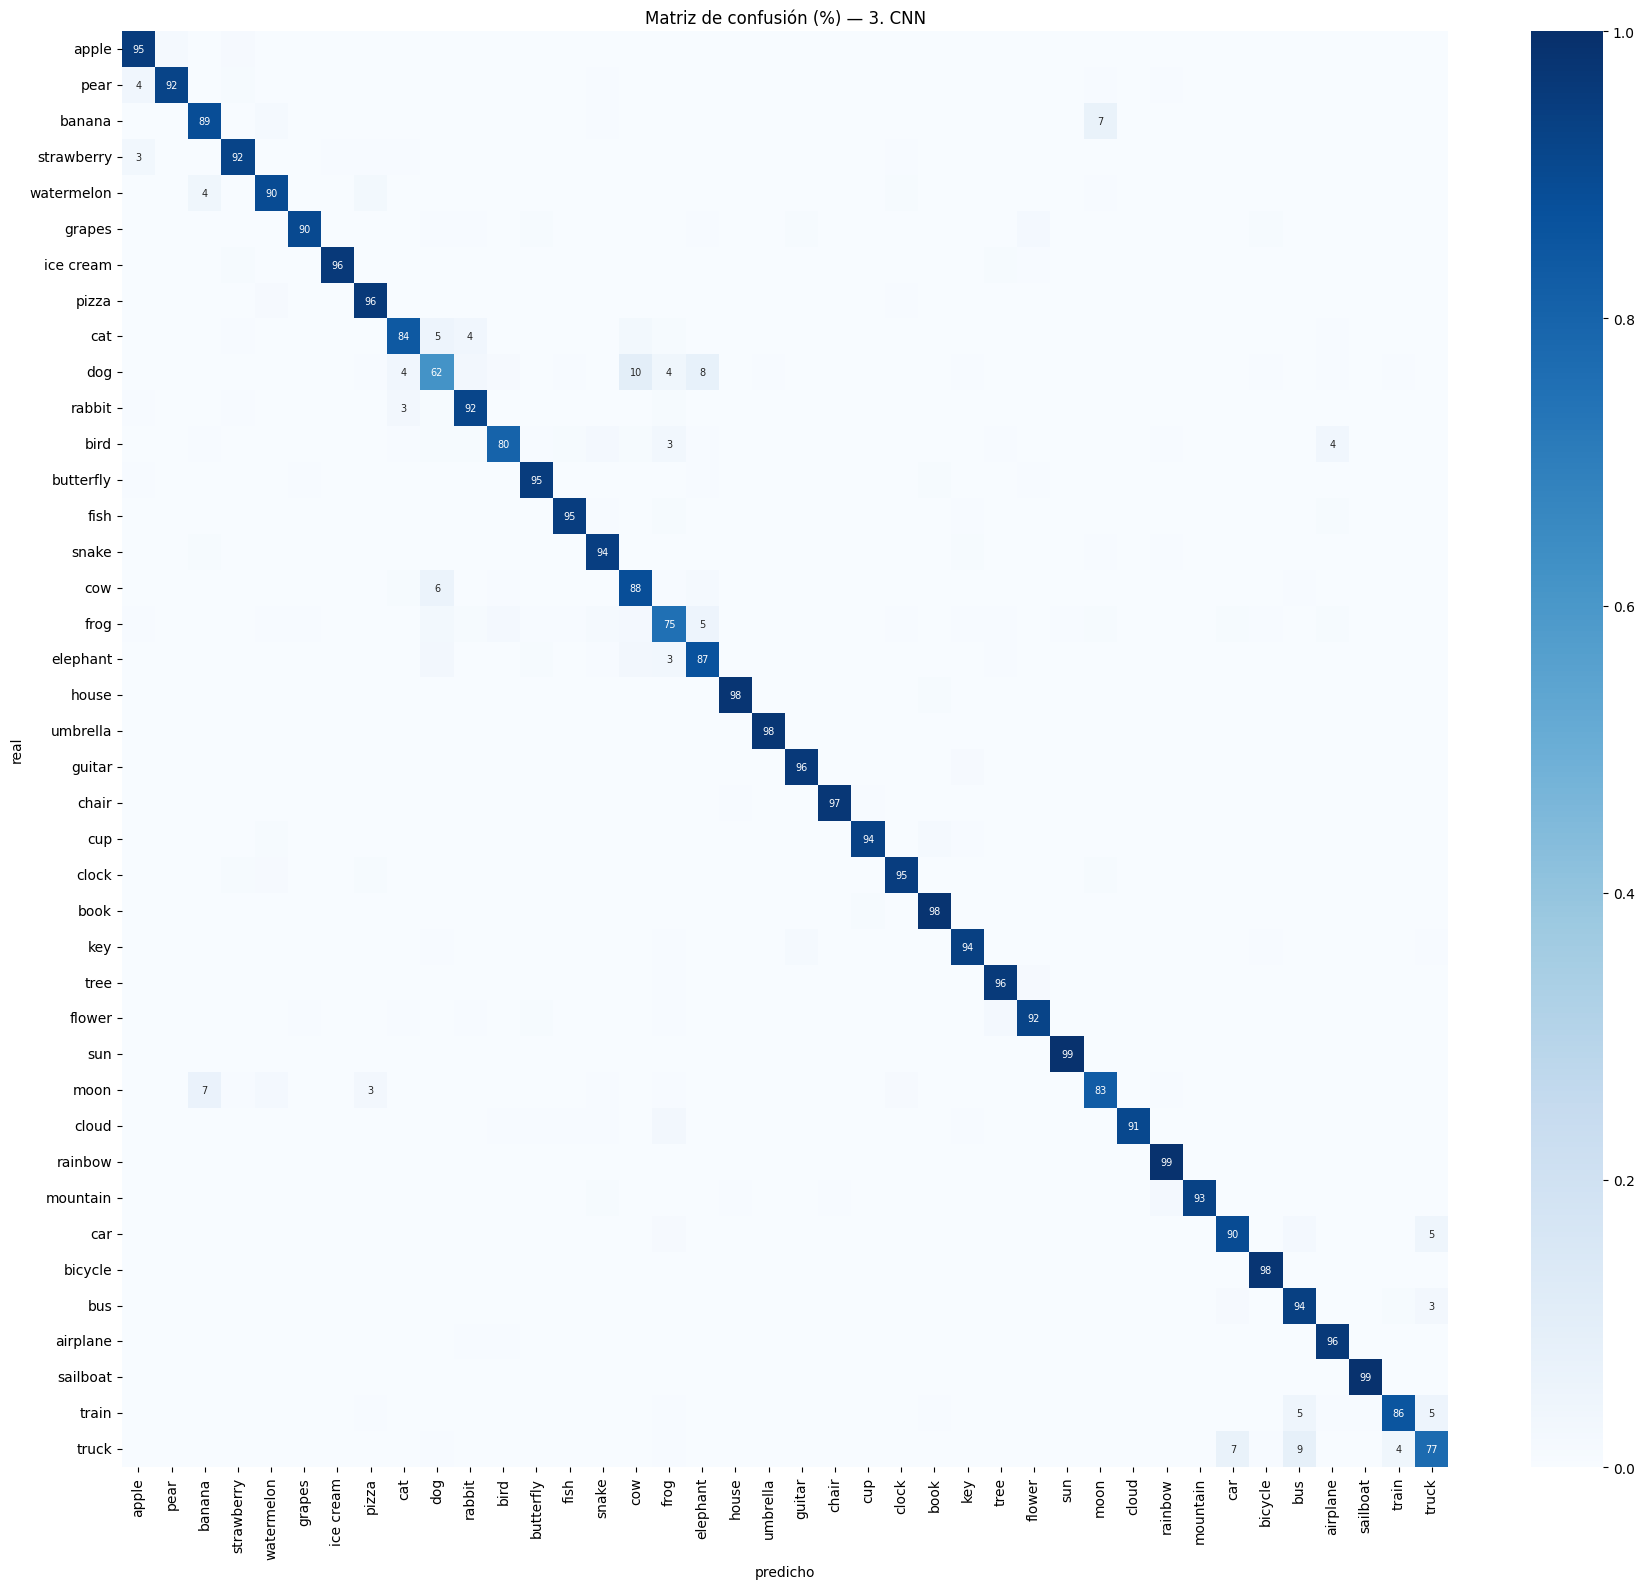

In [12]:
cm = confusion_matrix(y_test, pred, normalize="true")
plt.figure(figsize=(max(11, 0.45 * N), max(9, 0.4 * N)))
sns.heatmap(cm, xticklabels=CLASES, yticklabels=CLASES, cmap="Blues", vmin=0, vmax=1,
            annot=np.where(cm >= 0.03, np.round(cm * 100).astype(int).astype(str), ""), fmt="", annot_kws={"size": 7})
plt.xlabel("predicho"); plt.ylabel("real"); plt.title(f"Matriz de confusión (%) — {mejor_nombre}")
plt.tight_layout(); plt.show()

In [13]:
# Las confusiones más frecuentes
pares = [(CLASES[i], CLASES[j], cm[i, j]) for i in range(N) for j in range(N) if i != j]
top = pd.DataFrame(sorted(pares, key=lambda t: -t[2])[:10], columns=["real", "lo confunde con", "% de los dibujos"])
top["% de los dibujos"] = (top["% de los dibujos"] * 100).round(1)
top

,real,lo confunde con,% de los dibujos
0,dog,cow,10.2
1,truck,bus,8.8
2,dog,elephant,8.2
3,banana,moon,7.4
4,truck,car,7.4
5,moon,banana,6.9
6,cow,dog,6.2
7,train,truck,5.2
8,frog,elephant,5.2
9,cat,dog,5.1


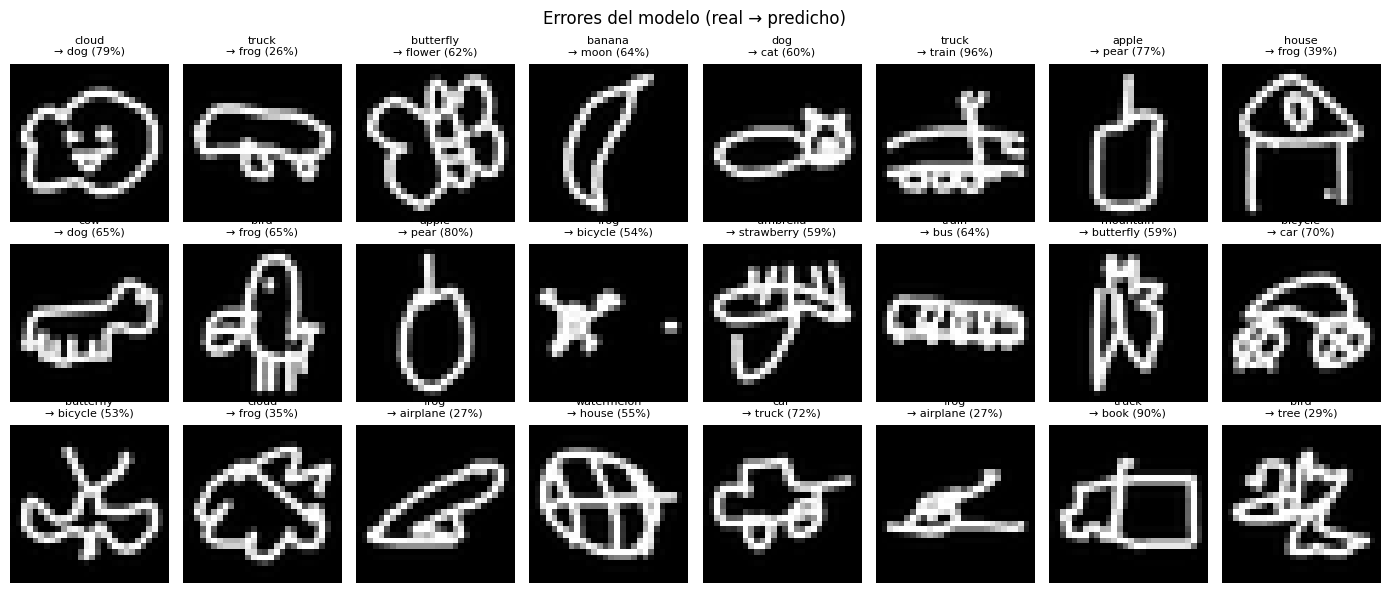

In [14]:
# Ejemplos de errores: real -> predicho (confianza)
errores = np.where(pred != y_test)[0]
sel = np.random.default_rng(SEED).choice(errores, min(24, len(errores)), replace=False)
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax in axes.flat: ax.axis("off")
for ax, i in zip(axes.flat, sel):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"{CLASES[y_test[i]]}\n→ {CLASES[pred[i]]} ({prob[i].max():.0%})", fontsize=8)
plt.suptitle("Errores del modelo (real → predicho)"); plt.tight_layout(); plt.show()

## 6. Pruebas difíciles: dibujos no reconocidos y dibujos de Colombia

- **No reconocidos:** el juego de Google no los adivinó a tiempo. Representan a quien dibuja mal o incompleto, que es parte del público de la app.
- **Colombia:** dibujos de jugadores en Colombia que el modelo nunca vio.

In [15]:
def evaluar_conjunto(X, y_, nombre):
    p = mejor.predict(X[..., None], batch_size=512, verbose=0)
    return {"conjunto": nombre, "dibujos": len(y_), "accuracy": accuracy_score(y_, p.argmax(1)),
            "top-3": np.mean([y_[i] in np.argsort(p[i])[-3:] for i in range(len(y_))]),
            "F1 macro": f1_score(y_, p.argmax(1), average="macro")}, p

filas, probs = [], {}
for X_, y_, nom in [(X_test, y_test, "prueba normal"), (X_noreco, y_noreco, "no reconocidos"),
                    (X_col[col_reco], y_col[col_reco], "Colombia (reconocidos)"),
                    (X_col[~col_reco], y_col[~col_reco], "Colombia (no reconocidos)")]:
    if len(y_):
        f, p = evaluar_conjunto(X_, y_, nom); filas.append(f); probs[nom] = (p, y_)
pruebas = pd.DataFrame(filas).set_index("conjunto")
pruebas.style.format({"accuracy": "{:.3f}", "top-3": "{:.3f}", "F1 macro": "{:.3f}"})

,dibujos,accuracy,top-3,F1 macro
conjunto,,,,
prueba normal,48000,0.914,0.982,0.914
no reconocidos,40000,0.428,0.618,0.431
Colombia (reconocidos),7219,0.924,0.987,0.924
Colombia (no reconocidos),513,0.483,0.684,0.410


In [16]:
# ¿En qué palabras cae más el modelo con los dibujos difíciles?
p_nr, y_nr = probs["no reconocidos"]
acc_normal = pd.Series([(pred[y_test == c] == c).mean() for c in range(N)], index=CLASES)
acc_dificil = pd.Series([(p_nr.argmax(1)[y_nr == c] == c).mean() if (y_nr == c).any() else np.nan for c in range(N)], index=CLASES)
caida = pd.DataFrame({"normal": acc_normal, "no reconocidos": acc_dificil})
caida["caída"] = caida["normal"] - caida["no reconocidos"]
caida.sort_values("caída", ascending=False).style.format("{:.2f}")

,normal,no reconocidos,caída
pear,0.93,0.08,0.84
cloud,0.91,0.17,0.73
clock,0.95,0.25,0.70
mountain,0.93,0.27,0.67
apple,0.95,0.31,0.64
ice cream,0.96,0.34,0.63
umbrella,0.97,0.38,0.60
butterfly,0.95,0.36,0.59
fish,0.95,0.36,0.58
sailboat,0.99,0.42,0.56


## 7. "No estoy segura": umbral de confianza

Si la probabilidad más alta es baja, es mejor que la app diga *"no te entendí, ¿lo intentas otra vez?"* que adivinar mal. El umbral se escoge con **validación** (no con prueba) y luego se revisa en prueba.

Umbral elegido en validación: 0.77


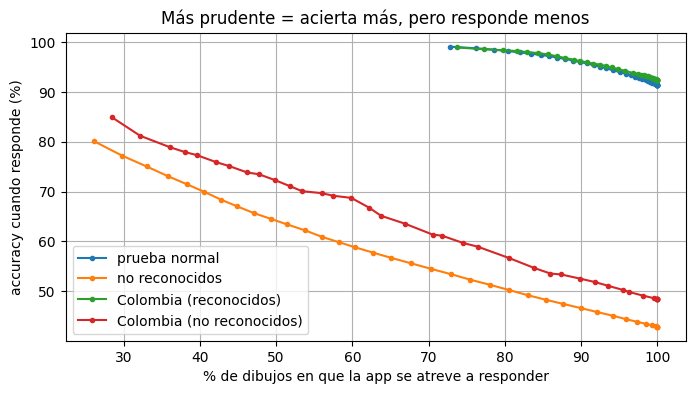

prueba normal                responde  85.8 % | acierta  97.2 % cuando responde
no reconocidos               responde  44.9 % | acierta  67.0 % cuando responde
Colombia (reconocidos)       responde  86.8 % | acierta  97.2 % cuando responde
Colombia (no reconocidos)    responde  46.2 % | acierta  73.8 % cuando responde


In [17]:
prob_val = mejor.predict(X_val[..., None], batch_size=512, verbose=0)
umbrales = np.linspace(0, 0.95, 39)
def curva(p, y_):
    conf, ok = p.max(1), p.argmax(1) == y_
    return pd.DataFrame({"umbral": umbrales,
                         "% que responde": [100 * (conf >= u).mean() for u in umbrales],
                         "accuracy cuando responde": [100 * ok[conf >= u].mean() if (conf >= u).any() else np.nan for u in umbrales]})
cv = curva(prob_val, y_val)

OBJETIVO = 97  # queremos acertar al menos 97 % de las veces que la app responde (más prudente)
UMBRAL = float(cv.loc[cv["accuracy cuando responde"] >= OBJETIVO, "umbral"].min()) if (cv["accuracy cuando responde"] >= OBJETIVO).any() else 0.5
print(f"Umbral elegido en validación: {UMBRAL:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
for nom, (p, y_) in probs.items():
    c = curva(p, y_)
    ax.plot(c["% que responde"], c["accuracy cuando responde"], marker=".", label=nom)
ax.set_xlabel("% de dibujos en que la app se atreve a responder"); ax.set_ylabel("accuracy cuando responde (%)")
ax.grid(True); ax.legend(); ax.set_title("Más prudente = acierta más, pero responde menos"); plt.show()

for nom, (p, y_) in probs.items():
    conf, ok = p.max(1), p.argmax(1) == y_
    r = conf >= UMBRAL
    print(f"{nom:28s} responde {100*r.mean():5.1f} % | acierta {100*ok[r].mean():5.1f} % cuando responde")

## 8. Exportar para la app

In [18]:
CARPETA = BASE / "modelo_app"
CARPETA.mkdir(exist_ok=True)
mejor.save(CARPETA / "modelo_dibujos.keras")
json.dump(PALABRAS, open(CARPETA / "palabras.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
shutil.copy(BASE / "temas.json", CARPETA / "temas.json")
json.dump({"umbral": UMBRAL, "modelo": mejor_nombre, "tf": tf.__version__}, open(CARPETA / "config.json", "w"), indent=2)
shutil.copy(BASE / "dibujos.py", CARPETA / "dibujos.py")
tabla.to_csv(CARPETA / "comparacion_modelos.csv"); pruebas.to_csv(CARPETA / "pruebas_dificiles.csv")

# Verificación: el modelo guardado carga y predice igual
recargado = keras.models.load_model(CARPETA / "modelo_dibujos.keras")
assert np.allclose(recargado.predict(X_test[:64, ..., None], verbose=0), prob[:64], atol=1e-4)
print("Modelo guardado y verificado. TensorFlow", tf.__version__)

if USAR_DRIVE:
    shutil.copytree(CARPETA, DRIVE / "modelo_app", dirs_exist_ok=True)
    print("Copiado a", DRIVE / "modelo_app")

Modelo guardado y verificado. TensorFlow 2.21.0
Copiado a /content/drive/MyDrive/proyecto_dibujos/modelo_app


## Resumen

*(Completar con los números de la ejecución.)*
- Mejor modelo (elegido por validación): ___ con F1 macro ___ en prueba (azar: 1/40 = 0,025).
- La CNN supera a la ANN en ___ puntos porque ___.
- Transfer learning: ___ (¿ayudó o no?, ¿por qué?).
- Confusiones más comunes: ___.
- Con dibujos no reconocidos el accuracy baja de ___ a ___; con dibujos de Colombia queda en ___.
- Con umbral ___ la app responde en ___ % de los dibujos y acierta ___ % de las veces.